# 11 · Robustness checks on the precursor fit

Notebooks 08–10 reproduce Dichiara's Band fit, but some choices and claims in them were only
partly tested. This notebook tests them one at a time, following an outside review of the code:

1. **Background exposure convention**: is background counts = fitted rate × live time right?
2. **P-stat vs PG-stat** (and W-stat): does treating the background as known matter?
3. **Nearest vs interpolated response**
4. **Background polynomial order**, 1 to 4
5. **Channel cuts**: which cuts give Dichiara's 480 d.o.f., and how much does E_peak depend on them?
6. **Errors**: are GDT's symmetric errors too small, and why? Checked against simulated spectra.
7. **Residual definition**: mine vs GDT's
8. **Band + blackbody**: how often does a Band-only spectrum give ΔC ≥ 27 by chance?

The reference fit throughout is the one from notebook 09: P-stat, NaI 8–900 keV, BGO 200 keV–40 MeV,
nearest DRM, cubic background.

In [1]:
import inspect
import warnings
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

from gdt.core.spectra.functions import Band, BlackBody
from gdt.core.spectra.fitting import (SpectralFitter, SpectralFitterPstat,
                                      SpectralFitterPgstat, SpectralFitterCstat)
from gdt.core.background.binned import Polynomial
from gdt.core.binning.unbinned import bin_by_edges
from gdt.missions.fermi.gbm.tte import GbmTte
from gdt.missions.fermi.gbm.response import GbmRsp2

from settings import (CODE_DIR, DATA_DIR, BURST_ID, SPECTRAL_DETECTORS, FIT_RANGE_NAI,
                      FIT_RANGE_BGO, FLUX_RANGE, PRECURSOR, BKG_WINDOWS, BKG_ORDER, FIGURE_DIR)
from spectral_fit_tools import (load_spectra, channel_mask, fit_model, cstat, covariance,
                                energy_flux, make_spectrum, simulate_pha)
from lightcurve_tools import tte_path, fit_background

SPECTRUM_DIR = CODE_DIR / "spectra"
phas, baks, rsps = load_spectra(SPECTRUM_DIR, BURST_ID, SPECTRAL_DETECTORS)
def fit_range(det):
    return FIT_RANGE_BGO if det.startswith("b") else FIT_RANGE_NAI
masks = [channel_mask(r, fit_range(d)) for r, d in zip(rsps, SPECTRAL_DETECTORS)]

BAND_START = [[1.5, 170.0, -0.6, -2.9, 100.0]]
band = Band()
ref = fit_model(phas, baks, rsps, masks, band, BAND_START)
ref_full = list(band.default_values)            # best fit, Epiv included

def show(label, f):
    p = f.parameters
    print(f"{label:34s} Epeak {p[1]:7.2f}  alpha {p[2]:7.4f}  beta {p[3]:6.3f}  "
          f"C-stat {cstat(f):7.1f}/{f.dof}")

show("reference (notebook 09)", ref)

reference (notebook 09)            Epeak  170.27  alpha -0.6332  beta -2.953  C-stat   568.7/484


## 1. Background exposure convention

Notebook 08 sets background counts in the precursor = fitted rate × **live time** of the precursor.
That's only right if the polynomial is a rate per second of *live* time. GDT's polynomial fitter
(which its docstring says is adapted from RMfit's) says so explicitly:

In [2]:
source = inspect.getsource(Polynomial.fit)
for line in source.splitlines():
    if "livetime" in line or "Adapted" in line:
        print(line.strip())

Adapted from the RMfit polynomial fitter.
# 1) rate * livetime = counts
# 3) variance of rate = variance of counts/livetime^2 = rate/livetime
variance = self._rate / self._livetime[:, np.newaxis]
variance = model / self._livetime[:, np.newaxis]


So the model is fitted to counts/live time, and counts = rate × live time. As a check on real data,
predict the counts in a quiet stretch that was **not** used in the background fit
(−6.9 to −1.0 s, just before the precursor) both ways, and compare with what was recorded.
Away from the burst the live fraction is ~0.99, so the two predictions differ by only ~1%. That is
about 1σ per detector, so the four detectors are summed.

In [3]:
quiet = (-6.9, -1.0)
observed = live_pred = wall_pred = 0.0
for det in SPECTRAL_DETECTORS:
    tte = GbmTte.open(tte_path(DATA_DIR, BURST_ID, det))
    pha_q = tte.to_phaii(bin_by_edges, np.array(quiet)).to_pha(time_ranges=[quiet])
    tte.close()
    fitter, _ = fit_background(DATA_DIR, BURST_ID, det, BKG_WINDOWS, BKG_ORDER)
    rate = np.sum(fitter.interpolate_bins(np.array([quiet[0]]), np.array([quiet[1]])).rates)
    n = pha_q.data.counts.sum()
    observed += n
    live_pred += rate * pha_q.exposure
    wall_pred += rate * (quiet[1] - quiet[0])
    print(f"{det}: observed {n:6.0f}, rate x live time {rate * pha_q.exposure:8.1f}, "
          f"rate x wall time {rate * (quiet[1] - quiet[0]):8.1f}  (live fraction "
          f"{pha_q.exposure / (quiet[1] - quiet[0]):.4f})")
err = np.sqrt(observed)
print(f"all four: observed {observed:.0f} +/- {err:.0f}; live-time prediction is "
      f"{(observed - live_pred) / err:+.1f} sigma off, wall-time prediction {(observed - wall_pred) / err:+.1f} sigma off")

n6: observed   5427, rate x live time   5419.0, rate x wall time   5432.8  (live fraction 0.9975)


n8: observed   8223, rate x live time   8097.8, rate x wall time   8129.3  (live fraction 0.9961)


na: observed   6186, rate x live time   6175.7, rate x wall time   6193.3  (live fraction 0.9972)


b1: observed   6981, rate x live time   7019.1, rate x wall time   7043.8  (live fraction 0.9965)
all four: observed 26817 +/- 164; live-time prediction is +0.6 sigma off, wall-time prediction +0.1 sigma off


## 2. P-stat vs PG-stat vs W-stat

* **P-stat** (`SpectralFitterPstat`): Poisson data, background model known exactly. Used in 09/10.
* **PG-stat** (`SpectralFitterPgstat`): Poisson data, background known to within its Gaussian
  error. GDT's documentation recommends it for GBM.
* **W-stat** (`SpectralFitterCstat`): Poisson data, background a Poisson measurement. By default
  GDT gives that measurement the source exposure (0.38 s), which doesn't describe a polynomial fitted
  to ~190 s.

The background model errors here are ~2 counts per detector against hundreds of background counts,
so P-stat and PG-stat should agree.

In [4]:
def refit(fitter_class, rsp_list=rsps, bak_list=baks, mask_list=masks):
    f = fitter_class(phas, bak_list, rsp_list, channel_masks=mask_list, method="SLSQP")
    b = Band()
    b.default_values = list(ref_full)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f.fit(b, options={"maxiter": 2000})
    return f

show("P-stat (background known)", ref)
show("PG-stat (Gaussian background)", refit(SpectralFitterPgstat))
show("W-stat (GDT 'Cstat', default)", refit(SpectralFitterCstat))

P-stat (background known)          Epeak  170.27  alpha -0.6332  beta -2.953  C-stat   568.7/484
PG-stat (Gaussian background)      Epeak  170.27  alpha -0.6334  beta -2.955  C-stat   566.3/484


W-stat (GDT 'Cstat', default)      Epeak  172.94  alpha -0.6473  beta -3.147  C-stat   460.8/484


## 3. Nearest vs interpolated response

The precursor sits inside one DRM interval (−7.49 to +30.40 s). GDT can also interpolate between
the DRMs either side, to the precursor's centre.

In [5]:
interp = [GbmRsp2.open(DATA_DIR / f"glg_cspec_{d}_{BURST_ID}_v02.rsp2").interpolate(np.mean(PRECURSOR))
          for d in SPECTRAL_DETECTORS]
show("nearest DRM", ref)
show("interpolated DRM", refit(SpectralFitterPstat, rsp_list=interp))

nearest DRM                        Epeak  170.27  alpha -0.6332  beta -2.953  C-stat   568.7/484
interpolated DRM                   Epeak  170.81  alpha -0.6218  beta -2.953  C-stat   567.7/484


## 4. Background polynomial order

Rebuild the background with orders 1 to 4 (same quiet windows) and refit. `make_spectrum` repeats
notebook 08's steps; order 3 should give back exactly notebook 08's spectra.

In [6]:
order_rows = []
for order in (1, 2, 3, 4):
    bkg_list, chi2s = [], []
    for det, pha in zip(SPECTRAL_DETECTORS, phas):
        pha_o, bkg_o, red_chi2 = make_spectrum(DATA_DIR, BURST_ID, det, PRECURSOR, BKG_WINDOWS, order)
        assert np.array_equal(pha_o.data.counts, pha.data.counts)
        bkg_list.append(bkg_o)
        chi2s.append(red_chi2)
    if order == 3:
        same = all(np.allclose(b.counts, k.data.counts) for b, k in zip(bkg_list, baks))
        print(f"order 3 reproduces notebook 08's background: {same}")
    total_bkg = sum(b.counts.sum() for b in bkg_list)
    f = refit(SpectralFitterPstat, bak_list=bkg_list)
    order_rows.append((order, *f.parameters[1:4]))
    show(f"order {order} (bkg chi2 {min(chi2s):.3f}-{max(chi2s):.3f}, {total_bkg:.0f} cts)", f)

order 1 (bkg chi2 0.954-0.991, 1704 cts) Epeak  170.58  alpha -0.6372  beta -2.957  C-stat   568.6/484


order 2 (bkg chi2 0.954-0.993, 1704 cts) Epeak  170.27  alpha -0.6347  beta -2.953  C-stat   568.5/484


order 3 reproduces notebook 08's background: True
order 3 (bkg chi2 0.956-0.995, 1706 cts) Epeak  170.27  alpha -0.6332  beta -2.953  C-stat   568.7/484


order 4 (bkg chi2 0.957-0.995, 1705 cts) Epeak  170.27  alpha -0.6329  beta -2.952  C-stat   568.8/484


## 5. Channel cuts and Dichiara's 480 d.o.f.

My cuts give 484 d.o.f.; Dichiara quote 480. Search a grid of plausible cuts for those giving exactly
480 (484 channels), using three selection rules (channel overlaps the range / channel centre inside /
channel fully inside) and two sets of channel energies (the response's, or the TTE data file's, which
differ by 1–3%; RMfit would select on the data file's).

In [7]:
edges = {}
for det, rsp in zip(SPECTRAL_DETECTORS, rsps):
    tte = GbmTte.open(tte_path(DATA_DIR, BURST_ID, det))
    edges[det, "response"] = (np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges()))
    edges[det, "TTE file"] = (np.asarray(tte.ebounds.low_edges()), np.asarray(tte.ebounds.high_edges()))
    tte.close()

def select(det, energies, rule, erange):
    lo, hi = edges[det, energies]
    centre = np.sqrt(lo * hi)
    mask = {"overlap": (hi > erange[0]) & (lo < erange[1]),
            "centre": (centre > erange[0]) & (centre < erange[1]),
            "inside": (lo >= erange[0]) & (hi <= erange[1])}[rule]
    mask[0] = mask[-1] = False
    return mask

grid = itertools.product(["response", "TTE file"], ["overlap", "centre", "inside"],
                         [8, 8.5, 9, 10], [850, 900, 950, 1000], [200, 220, 250, 300],
                         [30000, 38000, 40000, 45000])
cuts = []
for energies, rule, nai_lo, nai_hi, bgo_lo, bgo_hi in grid:
    m = [select(d, energies, rule, (bgo_lo, bgo_hi) if d.startswith("b") else (nai_lo, nai_hi))
         for d in SPECTRAL_DETECTORS]
    if sum(x.sum() for x in m) == 484:
        f = refit(SpectralFitterPstat, mask_list=m)
        cuts.append((abs(cstat(f) - 563.1), energies, rule, nai_lo, nai_hi, bgo_lo, bgo_hi,
                     *f.parameters[1:4], cstat(f)))
cuts.sort(key=lambda r: r[0])
print(f"{len(cuts)} cut combinations give 480 d.o.f.; closest to Dichiara's C-stat of 563.1:")
for r in cuts[:5]:
    print(f"  {r[1]:8s} {r[2]:7s} NaI {r[3]}-{r[4]}, BGO {r[5]}-{r[6]} keV: Epeak {r[7]:6.1f}  "
          f"alpha {r[8]:6.3f}  beta {r[9]:5.2f}  C-stat {r[10]:.1f}/480")
epk = np.array([r[7] for r in cuts])
print(f"Epeak over all {len(cuts)}: {epk.min():.1f} to {epk.max():.1f} keV "
      f"(median {np.median(epk):.1f}); BGO from 200 keV only: "
      f"{epk[[r[5] == 200 for r in cuts]].min():.1f} to {epk[[r[5] == 200 for r in cuts]].max():.1f} keV")

75 cut combinations give 480 d.o.f.; closest to Dichiara's C-stat of 563.1:
  TTE file overlap NaI 8-900, BGO 200-30000 keV: Epeak  170.3  alpha -0.633  beta -2.95  C-stat 562.4/480
  response overlap NaI 9-900, BGO 200-40000 keV: Epeak  170.3  alpha -0.629  beta -2.95  C-stat 564.9/480
  response overlap NaI 8-850, BGO 200-45000 keV: Epeak  170.3  alpha -0.633  beta -2.96  C-stat 565.1/480
  TTE file overlap NaI 9-900, BGO 200-38000 keV: Epeak  170.3  alpha -0.629  beta -2.95  C-stat 565.9/480
  TTE file inside  NaI 9-1000, BGO 220-38000 keV: Epeak  165.1  alpha -0.616  beta -2.87  C-stat 560.0/480
Epeak over all 75: 152.1 to 170.3 keV (median 165.1); BGO from 200 keV only: 165.3 to 170.3 keV


## 6. Are GDT's symmetric errors too small? Why?

**6a. A toy test of GDT's Hessian code.** GDT computes the Hessian with nested finite differences
(`_hessian` → `_mixed_pderiv` → `_pderiv`). Both inner helpers write the trial value into the *same*
parameter array and never put the original back. In the nested derivative this leaves the inner
parameter shifted between the outer evaluations. To test this without any spectra, give GDT's own
`_hessian` a function whose Hessian is known exactly:
ln L = −(a x² + b x y + c y²), so −∂²ln L/∂x∂y = b.

In [8]:
class Quadratic(SpectralFitter):
    # Only what _hessian needs: _fold_model returns ln L
    def __init__(self, a, b, c):
        self.a, self.b, self.c = a, b, c
    def _fold_model(self, function, params):
        x, y = params
        return -(self.a * x**2 + self.b * x * y + self.c * y**2)

class TwoParams:
    delta_rel = [0.01, 0.01]
    delta_abs = [0.1, 0.1]
    def fit_eval(self, params, x):
        return None

a, b, c = 3.0, 1.5, 2.0
x0 = np.array([1.0, 0.2])
gdt_hess = -Quadratic(a, b, c)._hessian(x0.copy(), TwoParams())
dx = 0.01 * np.abs(x0)
print("true    -Hessian:", [[2 * a, b], [b, 2 * c]])
print("GDT     -Hessian:", np.round(gdt_hess, 4).tolist())
print(f"predicted off-diagonal if the inner parameter drifts by 2 steps: "
      f"b + 2a dx/dy = {b + 2 * a * dx[0] / dx[1]:.4f}")

true    -Hessian: [[6.0, 1.5], [1.5, 4.0]]
GDT     -Hessian: [[6.0, 31.5], [31.5, 4.0]]
predicted off-diagonal if the inner parameter drifts by 2 steps: b + 2a dx/dy = 31.5000


**6b. The same effect in the real fit.** If that's the mechanism, GDT's off-diagonal terms should equal
the correct ones plus H_ii Δx_i/Δx_j (i < j, Δx = 1% of each parameter).

In [9]:
mine = np.linalg.inv(covariance(ref))          # -Hessian of ln L from central differences
gdt = -ref.hessian
dx = 0.01 * np.abs(ref.parameters)
predicted = mine.copy()
for i, j in itertools.combinations(range(4), 2):
    predicted[i, j] = predicted[j, i] = mine[i, j] + mine[i, i] * dx[i] / dx[j]
np.set_printoptions(precision=1, suppress=True, linewidth=120)
print("GDT -Hessian\n", gdt)
print("correct -Hessian + predicted drift term\n", predicted)
print("correct -Hessian (central differences)\n", mine)

GDT -Hessian
 [[3619.7   70.5 4384.1 2264.7]
 [  70.5    0.5   97.    34.6]
 [4384.1   97.  7700.9 1321.2]
 [2264.7   34.6 1321.2  229.3]]
correct -Hessian + predicted drift term
 [[3619.8   71.1 4561.9 2301.2]
 [  71.1    0.5   99.5   35.5]
 [4561.9   99.5 7701.2 1338.1]
 [2301.2   35.5 1338.1  233.6]]
correct -Hessian (central differences)
 [[ 3619.8    36.4 -4759.5   302.7]
 [   36.4     0.5   -37.4     6.1]
 [-4759.5   -37.4  7701.2  -313. ]
 [  302.7     6.1  -313.    233.6]]


**6c. Simulations: the direct test of every error estimate.** Draw 1000 fake spectra from the best-fit
Band model (Poisson counts on top of the background model, with the real responses and exposures),
fit each one exactly as the real data were, and look at the scatter of the fitted values. That scatter
*is* the 1σ error, whatever any Hessian says. The same simulations are used for the Band + BB test in
section 8, and for the flux error (notebook 10 propagates it with a Gaussian approximation).

They take ~20 minutes, so the results are saved to `spectra/sim_band_null.npz` and reloaded; delete
that file to rerun them.

In [10]:
N_SIM = 1000
sim_file = SPECTRUM_DIR / "sim_band_null.npz"
bb_starts = [[3e-4, 15.0], [1e-4, 30.0], [1e-3, 8.0], [5e-5, 50.0]]

if sim_file.exists():
    sims = dict(np.load(sim_file))
    print(f"loaded {len(sims['band'])} simulations from {sim_file.name}")
else:
    rng = np.random.default_rng(2026)
    rows_band, rows_dc, rows_flux = [], [], []
    for k in range(N_SIM):
        fake = [simulate_pha(p, b, r, band, ref_full, rng) for p, b, r in zip(phas, baks, rsps)]
        f_band = fit_model(fake, baks, rsps, masks, Band(), [ref_full])
        bb = Band() + BlackBody()
        f_bb = fit_model(fake, baks, rsps, masks, bb, [ref_full + s for s in bb_starts])
        rows_band.append(f_band.parameters)
        rows_dc.append(cstat(f_band) - cstat(f_bb))
        rows_flux.append(energy_flux(Band(), f_band.parameters, FLUX_RANGE))
    sims = {"band": np.array(rows_band), "delta_c": np.array(rows_dc), "flux": np.array(rows_flux)}
    np.savez(sim_file, **sims)
    print(f"ran and saved {N_SIM} simulations")

loaded 1000 simulations from sim_band_null.npz


          truth  sim mean  sim scatter  my cov.     GDT  Dichiara
A         1.631     1.633        0.092    0.101   0.012          
Epeak   170.268   170.467        4.742    5.255   1.044       4.7
alpha    -0.633    -0.632        0.040    0.044   0.014      0.04
beta     -2.953    -2.965        0.098    0.095   0.022      0.09
flux      3.322     3.320        0.039   (x 1e-5; notebook 10 Gaussian propagation: 0.041; Dichiara 0.038)


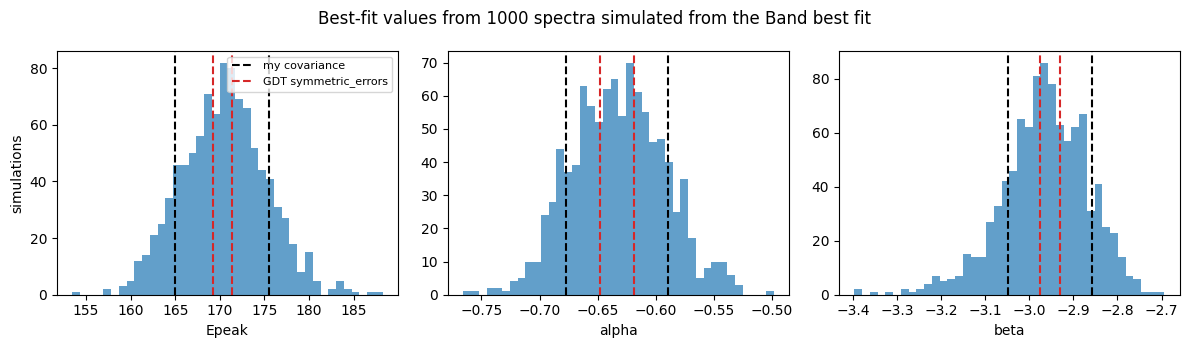

In [11]:
names = ["A", "Epeak", "alpha", "beta"]
sim_sd = sims["band"].std(axis=0)
cov_err = np.sqrt(np.diag(covariance(ref)))
gdt_err = ref.symmetric_errors
print(f"{'':6s}{'truth':>9s}{'sim mean':>10s}{'sim scatter':>13s}{'my cov.':>9s}{'GDT':>8s}{'Dichiara':>10s}")
for i, (n, d) in enumerate(zip(names, [None, 4.7, 0.04, 0.09])):
    print(f"{n:6s}{ref.parameters[i]:9.3f}{sims['band'][:, i].mean():10.3f}{sim_sd[i]:13.3f}"
          f"{cov_err[i]:9.3f}{gdt_err[i]:8.3f}{'' if d is None else d:>10}")
flux_best = energy_flux(Band(), ref.parameters, FLUX_RANGE)
print(f"flux  {flux_best / 1e-5:9.3f}{sims['flux'].mean() / 1e-5:10.3f}{sims['flux'].std() / 1e-5:13.3f}"
      f"   (x 1e-5; notebook 10 Gaussian propagation: 0.041; Dichiara 0.038)")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, i in zip(axes, (1, 2, 3)):
    ax.hist(sims["band"][:, i], bins=40, color="tab:blue", alpha=0.7)
    for k, (err, colour, label) in enumerate([(cov_err[i], "black", "my covariance"),
                                              (gdt_err[i], "tab:red", "GDT symmetric_errors")]):
        for sign in (-1, 1):
            ax.axvline(ref.parameters[i] + sign * err, color=colour, ls="--",
                       label=label if sign == 1 else None)
    ax.set_xlabel(names[i])
axes[0].legend(fontsize=8)
axes[0].set_ylabel("simulations")
fig.suptitle("Best-fit values from 1000 spectra simulated from the Band best fit")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_simulated_errors.png", dpi=200)
plt.show()

## 7. Residual definition

GDT's `fitter.residuals()` gives, per channel, (net − model counts) / σ with the **model** variance,
σ² = model + background + σ_B² (all in counts). An earlier version of notebook 10 used the **data**
variance, σ² = N + σ_B². With one channel per point that fails badly: high-energy channels with 0 or
1 count get a tiny σ and huge residuals. Notebook 10 had hidden this by grouping channels to ≥5σ
first. It now uses the model variance, like GDT. Check both definitions per channel against GDT.

n6: sum of squared residuals, GDT  100.2, model sigma  100.2, data sigma  1064.2  (122 channels, 20 with 0 or 1 count)
n8: sum of squared residuals, GDT  113.1, model sigma  113.1, data sigma  2739.4  (122 channels, 27 with 0 or 1 count)
na: sum of squared residuals, GDT  199.1, model sigma  199.1, data sigma  2450.9  (121 channels, 15 with 0 or 1 count)
b1: sum of squared residuals, GDT  123.7, model sigma  123.7, data sigma  1617.0  (123 channels, 72 with 0 or 1 count)


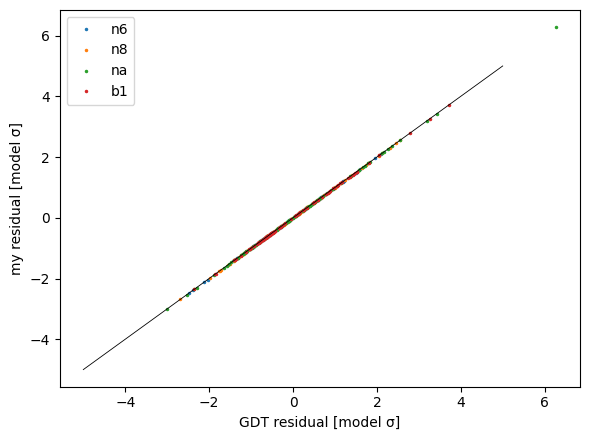

In [12]:
_, _, gdt_resid, _ = ref.residuals(sigma=True)
fig, ax = plt.subplots(figsize=(6, 4.5))
for det, pha, bak, rsp, mask, r_gdt in zip(SPECTRAL_DETECTORS, phas, baks, rsps, masks, gdt_resid):
    counts = np.asarray(pha.data.counts, dtype=float)
    bkg = np.asarray(bak.data.counts)
    bkg_var = np.asarray(bak.data.count_uncertainty)**2
    model = np.asarray(rsp.drm.fold_spectrum(band.eval, ref_full)) * pha.exposure
    model_sigma = ((counts - bkg - model) / np.sqrt(model + bkg + bkg_var))[mask]
    data_sigma = ((counts - bkg - model) / np.sqrt(counts + bkg_var))[mask]
    ax.plot(r_gdt, model_sigma, ".", ms=3, label=det)
    print(f"{det}: sum of squared residuals, GDT {np.sum(r_gdt**2):6.1f}, model sigma "
          f"{np.sum(model_sigma**2):6.1f}, data sigma {np.sum(data_sigma**2):7.1f}  "
          f"({mask.sum()} channels, {np.sum(counts[mask] <= 1):.0f} with 0 or 1 count)")
ax.plot([-5, 5], [-5, 5], color="black", lw=0.6)
ax.set_xlabel("GDT residual [model σ]")
ax.set_ylabel("my residual [model σ]")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Band + blackbody: how significant is ΔC = 27?

Fit Band + BB to the real data with the same four starting points as the simulations, then compare
the real ΔC with its distribution in the 1000 Band-only simulations. Each simulation was fitted with
both models, so this is the null distribution of ΔC directly, without leaning on Wilks' theorem.

This only tests *statistical* fluctuations. A systematic problem, such as an error in the response
around the iodine K-edge (33 keV) where n6 and n8 have little area, would not show up here.

real data: Delta C = 26.9 (Band 568.7 -> Band+BB 541.8)
simulations: Delta C >= 26.9 in 0 of 1000; largest 18.0; median 1.30
  90th percentile of simulated Delta C: 5.03  (chi2 with 2 dof: 4.61)
  99th percentile of simulated Delta C: 10.06  (chi2 with 2 dof: 9.21)
chi2 (2 dof) tail probability at 26.9: 1.5e-06


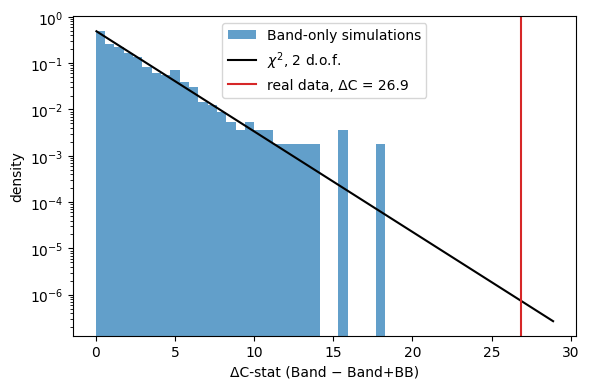

In [13]:
bb = Band() + BlackBody()
real_bb = fit_model(phas, baks, rsps, masks, bb, [ref_full + s for s in bb_starts])
dc_real = cstat(ref) - cstat(real_bb)
dc_sim = sims["delta_c"]
n_above = np.sum(dc_sim >= dc_real)
print(f"real data: Delta C = {dc_real:.1f} (Band {cstat(ref):.1f} -> Band+BB {cstat(real_bb):.1f})")
print(f"simulations: Delta C >= {dc_real:.1f} in {n_above} of {len(dc_sim)}; "
      f"largest {dc_sim.max():.1f}; median {np.median(dc_sim):.2f}")
for q in (0.9, 0.99):
    print(f"  {100 * q:.0f}th percentile of simulated Delta C: {np.quantile(dc_sim, q):.2f}  "
          f"(chi2 with 2 dof: {chi2.ppf(q, 2):.2f})")
print(f"chi2 (2 dof) tail probability at {dc_real:.1f}: {chi2.sf(dc_real, 2):.1e}")

fig, ax = plt.subplots(figsize=(6, 4))
bins = np.linspace(0, max(dc_real, dc_sim.max()) + 2, 50)
ax.hist(dc_sim, bins=bins, density=True, color="tab:blue", alpha=0.7, label="Band-only simulations")
x = np.linspace(0.05, bins[-1], 300)
ax.plot(x, chi2.pdf(x, 2), color="black", label=r"$\chi^2$, 2 d.o.f.")
ax.axvline(dc_real, color="tab:red", label=f"real data, ΔC = {dc_real:.1f}")
ax.set_yscale("log")
ax.set_xlabel("ΔC-stat (Band − Band+BB)")
ax.set_ylabel("density")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_band_bb_null.png", dpi=200)
plt.show()

### 8b. Is the BB fitting the iodine K-edge?

The simulations assume a perfect response, so they can't test a calibration problem. A direct check:
remove the NaI channels around the K-edge (33.2 keV) and refit both models. If the BB is fitting a
response feature there, its improvement should shrink.

In [14]:
def without(dets, erange):
    out = []
    for rsp, det, mask in zip(rsps, SPECTRAL_DETECTORS, masks):
        m = mask.copy()
        if det in dets:
            lo, hi = np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges())
            m &= ~((hi > erange[0]) & (lo < erange[1]))
        out.append(m)
    return out

for dets, erange in [([], None), (["na"], (30.0, 40.0)), (["n6", "n8", "na"], (30.0, 40.0)),
                     (["n6", "n8", "na"], (30.0, 45.0))]:
    m = masks if not dets else without(dets, erange)
    b_only = Band()
    f_band = fit_model(phas, baks, rsps, m, b_only, BAND_START)
    f_bb = fit_model(phas, baks, rsps, m, Band() + BlackBody(),
                     [list(b_only.default_values) + s for s in bb_starts])
    label = "all channels" if not dets else f"{'+'.join(dets)} without {erange[0]:.0f}-{erange[1]:.0f} keV"
    print(f"{label:34s} Band Epeak {f_band.parameters[1]:6.1f}, C-stat {cstat(f_band):6.1f}/{f_band.dof}; "
          f"adding BB: Delta C {cstat(f_band) - cstat(f_bb):5.1f}, kT {f_bb.parameters[-1]:4.1f} keV")

all channels                       Band Epeak  170.3, C-stat  568.7/484; adding BB: Delta C  26.9, kT 15.2 keV


na without 30-40 keV               Band Epeak  173.6, C-stat  512.8/477; adding BB: Delta C  16.9, kT 17.1 keV


n6+n8+na without 30-40 keV         Band Epeak  173.2, C-stat  498.6/463; adding BB: Delta C  17.5, kT 17.2 keV


n6+n8+na without 30-45 keV         Band Epeak  174.3, C-stat  492.4/456; adding BB: Delta C  15.4, kT 17.5 keV


Removing na's seven channels at 30–40 keV lowers the Band C-stat by ~56, about 8 per channel where
~1 would be expected, so the Band model fits those channels badly. Without them the BB improvement
falls from ~27 to ~17. The K-edge region explains part of the BB signal, but not all: ΔC ≈ 17 is
still near the top of the Band-only simulations (largest of 1000: 18.0). Band E_peak moves up by
~3 keV (0.7σ) when these channels go, a systematic worth keeping in mind.

## Summary

| Check | Result | Verdict |
|---|---|---|
| Background = rate × live time | GDT fits rate = counts / live time; quiet-interval test agrees within 1σ | consistent, but the data test can't distinguish (live fraction 0.997) |
| P-stat vs PG-stat | E_peak identical to 0.01 keV, α and β within 0.002 | background treatment doesn't matter here |
| Nearest vs interpolated DRM | E_peak +0.5 keV | negligible (0.1σ) |
| Background order 1–4 | E_peak within 0.3 keV | negligible |
| Channel cuts (480 d.o.f.) | 75 cuts give 480; E_peak 152–170 keV, 165–170 if BGO starts at 200 keV | **largest systematic**; exact cuts not recoverable |
| Errors | simulated scatter E_peak 4.7, α 0.040, β 0.098; my covariance 5.3, 0.044, 0.095; GDT 1.0, 0.014, 0.022 | GDT's symmetric errors too small; toy test shows why |
| Flux error | simulated 0.039 vs Gaussian propagation 0.041 (× 10⁻⁵) | Gaussian propagation fine |
| Residuals | model-σ residuals identical to GDT's | notebook 10 now uses these |
| Band + BB | 0 of 1000 Band-only sims reach ΔC = 26.9; without na 30–40 keV, ΔC ≈ 17 | statistically significant; partly a K-edge feature; open question |